In [80]:
import numpy as np
import scipy.stats
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ruídos

Ruídos normalmente consistem em valores que aparentemente não pertencem à distribuição que gerou o conjunto de dados à disposição [Faceli et al. 2011]. Vários podem ser os motivos para a ocorrência dos mesmos, desde erros na digitação ao tabular os dados, problemas de medição em instrumentos utilizados para coletar os dados ou, até mesmo, valores pouco comuns mas reais. Portanto, ao descartar objetos que apresentem valores ruidosos para um ou mais atributos, pode-se perder informações relevantes para o problema estudado.

A fim de reduzir a influência de ruídos nos atributos do conjunto de dados estudado, diversas técnicas podem ser aplicadas. Dentre elas, uma das mais simples consiste em dividir os valores de cada atributo em faixas, de modo que cada faixa contenha aproximadamente a mesma quantidade de valores. Em seguida, os valores contidos em cada faixa são substituídos por alguma medida que os sumarize como, por exemplo, a média. Um exemplo desta técnica é demonstrado a seguir.



In [81]:
dados = pd.read_csv('./data/breast-cancer.csv')

In [82]:
dados.head()

,sample_id,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,diagnosis
0,842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [83]:
dados.shape

(569, 32)

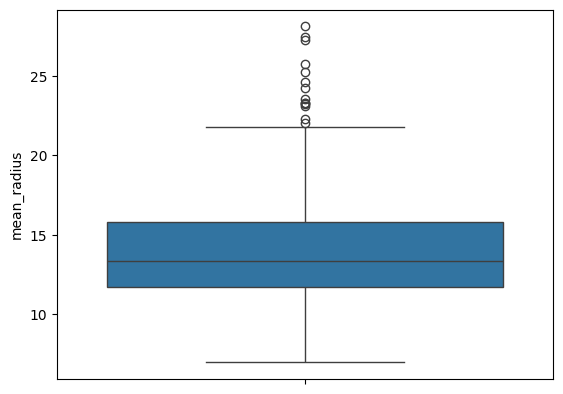

In [84]:
sns.boxplot(data=dados['mean_radius'])
plt.show()

In [85]:
# dividindo o atributo 'mean_radius' em 10 faixas
bins = pd.qcut(dados['mean_radius'], 10)

In [86]:
# a quantidade de valores aproximadamente igual em cada faixa pode ser comprovada pelo metodo value_counts
bins.value_counts()

mean_radius
(6.9799999999999995, 10.26]    58
(17.068, 19.53]                58
(15.056, 17.068]               57
(11.366, 12.012]               57
(12.726, 13.37]                57
(12.012, 12.726]               57
(14.058, 15.056]               57
(10.26, 11.366]                56
(13.37, 14.058]                56
(19.53, 28.11]                 56
Name: count, dtype: int64

In [87]:
# O metodo groupby permite que valores contidos na coluna de um DataFrame sejam agrupados segundo
# algum criterio. Neste exemplo, a coluna 'mean_radius' sera agrupada pelas faixas definidas pelo metodo qcut.
grupos = dados['mean_radius'].groupby(bins)

/tmp/ipykernel_6993/1628715859.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grupos = dados['mean_radius'].groupby(bins)


In [88]:
# obtendo a media de cada faixa
medias = grupos.mean()

In [89]:
# Obtendo a nova coluna.

# O metodo apply recebe como parametro uma funcao, aplica tal funcao a todos os seus elements e retorna
# um pandas.Series contendo os resultados.

# Neste caso, cada elemento de bins consiste no intervalo que o respectivo valor de 'mean_radius'
# pertence e, assim, a funcao informada em apply retornara a respectiva media de cada intervalo.
novo_mean_radius = bins.apply(lambda x : medias[x])

In [90]:
# por fim, a coluna 'mean_radius' do DataFrame original é atualizada
dados['mean_radius'] = novo_mean_radius

In [91]:
dados.head()

,sample_id,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,diagnosis
0,842302,18.324483,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,842517,21.453750,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,84300903,21.453750,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,84348301,11.691754,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,84358402,21.453750,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


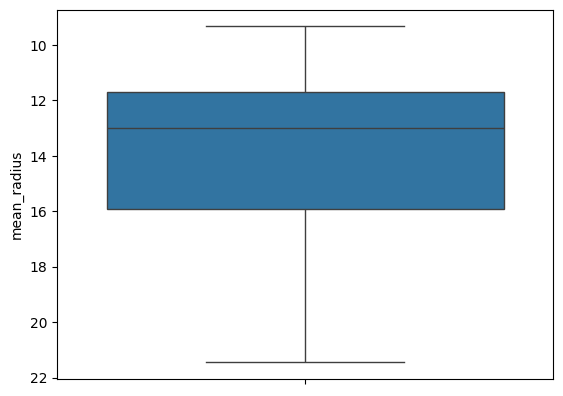

In [92]:
sns.boxplot(data=dados['mean_radius'])
plt.show()

# Transformação de Dados

## Transformação de dados simbólicos para dados numéricos

Diversas técnicas de Aprendizagem de dados exigem que os dados de entrada consistam apenas em valores numéricos. Entretanto, diversos conjuntos reais podem apresentar atributos qualitativos nominais ou ordinais, tornando assim necessário o emprego de técnicas que permitam a conversão de tais atributos.

No primeiro caso, quando houver a existência de atributos nominais, a inexistência de qualquer ordem deve persistir na conversão do atributo. Uma abordagem bastante conhecida e utililizada para isso consiste na codificação 1-de-c [Faceli et al. 2011]. Nela, considerando que um atributo possua c valores possíveis, são criados c novos atributos binários, onde cada posição indica um possível valor do atributo nominal original. Desse modo, apenas uma posição da nova sequência binária de cada objeto poderá ser igual a 1, indicando qual é o valor correspondente de um determinado objeto para o atributo original.

Em Python, tal conversão pode ser facilmente realizada por meio do método pandas.get_dummies, conforme demonstrado pelo exemplo a seguir.

In [93]:
# leitura dos dados
print('Número de linhas e colunas:', dados.shape)
# mostramos a última coluna
print('Coluna com as classes:\n', dados[dados.columns[-1]])

Número de linhas e colunas: (569, 32)
Coluna com as classes:
 0      malignant
1      malignant
2      malignant
3      malignant
4      malignant
         ...    
564    malignant
565    malignant
566    malignant
567    malignant
568       benign
Name: diagnosis, Length: 569, dtype: object


In [94]:
# armazena o nome das classes
classes = np.unique(dados[dados.columns[-1]])
number = 0 # valor que será usado para representar a clases
for i in classes:
    dados = dados.replace(i, number) # substitui cada valor da classe por number
    number = number + 1
print('Novos dados:')
print(dados[dados.columns[-1]])

Novos dados:
0      1
1      1
2      1
3      1
4      1
      ..
564    1
565    1
566    1
567    1
568    0
Name: diagnosis, Length: 569, dtype: int64


/tmp/ipykernel_6993/1935529393.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dados = dados.replace(i, number) # substitui cada valor da classe por number


In [95]:
data.head(5)

0    18.324483
1    21.453750
2    21.453750
3    11.691754
4    21.453750
Name: mean_radius, dtype: category
Categories (10, float64): [9.342052 < 10.951071 < 11.691754 < 12.357018 ... 14.605088 < 15.914561 < 18.324483 < 21.453750]